# Used Car Price Prediction: Production-Grade ML Pipeline
**Author:** Senior Machine Learning Engineer  
**Dataset:** Vehicle dataset from CarDekho (Kaggle)  
**Objective:** End-to-end regression pipeline predicting used car selling prices with calibrated feature engineering, leak-free preprocessing, target transformation, multi-model benchmarking, and diagnostic residual analysis.

## 1. Setup & Environment
Import core analytical, visualization, and machine learning libraries. Configure a consistent visual theme, suppress redundant warnings, and establish reproducibility with `random_state=42`.

In [1]:
# Import standard library and scientific computing stack
import os
import sys
import datetime
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Suppress minor warnings for clean presentation
warnings.filterwarnings('ignore')

# Set global seed for deterministic reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure plot aesthetics
sns.set_theme(style='whitegrid', palette='mako')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 110

print('Environment successfully configured with random_state=42.')

Environment successfully configured with random_state=42.


### Data Loading & Schema Inspection
Load the CarDekho dataset, adapt column names dynamically to standardized `snake_case`, and inspect memory usage and data types.

In [2]:
# Locate dataset across local workspace paths
data_candidates = [
    'data/CAR DETAILS FROM CAR DEKHO.csv',
    'Task-3-Car-Price-Prediction/data/CAR DETAILS FROM CAR DEKHO.csv',
    '../data/CAR DETAILS FROM CAR DEKHO.csv'
]
data_path = next((p for p in data_candidates if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError('Dataset CSV not found in expected data/ directories.')

df_raw = pd.read_csv(data_path)
print(f'Successfully loaded dataset from: {data_path}')
print(f'Initial Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns')
print(f'Memory footprint: {df_raw.memory_usage().sum() / 1024:.2f} KB\n')

# Standardize column headers to snake_case
col_alias = {
    'Car_Name': 'name', 'Year': 'year', 'Selling_Price': 'selling_price',
    'Present_Price': 'present_price', 'Kms_Driven': 'km_driven',
    'Fuel_Type': 'fuel', 'Seller_Type': 'seller_type',
    'Transmission': 'transmission', 'Owner': 'owner'
}
df_raw.rename(columns=lambda c: col_alias.get(c, c.strip().lower().replace(' ', '_')), inplace=True)

print('Standardized Column Headers:', df_raw.columns.tolist())
display(df_raw.head())

Successfully loaded dataset from: data/CAR DETAILS FROM CAR DEKHO.csv
Initial Shape: 4,340 rows, 8 columns
Memory footprint: 271.38 KB

Standardized Column Headers: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 2. Data Cleaning & Sanitization
Clean categorical values (strip spaces, lowercase, unify), detect and remove duplicate listings, handle missing values (median for numerics, mode for categoricals), and check for impossible records.

In [3]:
df = df_raw.copy()

# Strip whitespace and lowercase all string/categorical fields
cat_cols = ['name', 'fuel', 'seller_type', 'transmission', 'owner']
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.lower()

# Duplicate detection and removal
initial_records = len(df)
dup_count = df.duplicated().sum()
df.drop_duplicates(inplace=True)
print(f'Duplicates removed: {dup_count:,} ({dup_count/initial_records*100:.2f}% of raw records)')
print(f'Retained distinct records: {len(df):,}')

# Missing value audit
null_counts = df.isnull().sum()
print('\nMissing Value Audit:')
print(null_counts[null_counts > 0] if null_counts.any() else 'Zero null values detected across all columns.')

# Imputation logic (fallback safeguard adhering to standard practice)
# Numeric columns: impute with median (robust against skew/outliers)
# Categorical columns: impute with mode (most frequent category)
num_cols = df.select_dtypes(include=[np.number]).columns
for col in num_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
for col in cat_cols:
    if col in df.columns and df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)

# Sanity check for impossible values
current_year = datetime.datetime.now().year
impossible_mask = (
    (df['year'] < 1980) | (df['year'] > current_year) |
    (df['selling_price'] <= 0) | (df['km_driven'] < 0)
)
print(f'Impossible records detected and filtered: {impossible_mask.sum()}')
df = df[~impossible_mask].reset_index(drop=True)

Duplicates removed: 763 (17.58% of raw records)
Retained distinct records: 3,577

Missing Value Audit:
Zero null values detected across all columns.
Impossible records detected and filtered: 0


## 3. Feature Engineering
Derive domain-relevant predictors without hardcoding:
1. `car_age`: Derived dynamically from current system calendar year (`datetime.datetime.now().year - year`).
2. `brand`: Extracted from the first token of the vehicle name and normalized (e.g., `"maruti suzuki"` $\rightarrow$ `"maruti"`). Infrequent brands ($< 1\%$ share) are grouped into `"other"`.
3. `km_per_year`: Calculated as $\frac{\text{km\_driven}}{\max(\text{car\_age}, 1)}$ to capture annual vehicle wear intensity.

In [4]:
# 1. Derive dynamic car age (no hardcoded current year)
current_year = datetime.datetime.now().year
df['car_age'] = current_year - df['year']

# 2. Extract and standardize brand
df['brand'] = df['name'].apply(lambda x: str(x).strip().split()[0].lower())
# Normalize brand naming variations
brand_alias = {'marutisuzuki': 'maruti'}
df['brand'] = df['brand'].replace(brand_alias)

# Consolidate minor brands (<1% frequency) into 'other'
brand_frequencies = df['brand'].value_counts(normalize=True)
rare_brands = brand_frequencies[brand_frequencies < 0.01].index.tolist()
df['brand'] = df['brand'].apply(lambda b: 'other' if b in rare_brands else b)

# 3. Calculate annual mileage intensity
df['km_per_year'] = df['km_driven'] / np.maximum(df['car_age'], 1)

print(f'Current Year Reference: {current_year}')
print(f'Identified {len(df["brand"].unique())} primary brand groupings: {sorted(df["brand"].unique().tolist())}')
display(df[['name', 'brand', 'year', 'car_age', 'km_driven', 'km_per_year', 'selling_price']].head())

Current Year Reference: 2026
Identified 13 primary brand groupings: ['chevrolet', 'ford', 'honda', 'hyundai', 'mahindra', 'maruti', 'nissan', 'other', 'renault', 'skoda', 'tata', 'toyota', 'volkswagen']


,name,brand,year,car_age,km_driven,km_per_year,selling_price
0,maruti 800 ac,maruti,2007,19,70000,3684.210526,60000
1,maruti wagon r lxi minor,maruti,2007,19,50000,2631.578947,135000
2,hyundai verna 1.6 sx,hyundai,2012,14,100000,7142.857143,600000
3,datsun redigo t option,other,2017,9,46000,5111.111111,250000
4,honda amaze vx i-dtec,honda,2014,12,141000,11750.000000,450000


## 4. Exploratory Data Analysis (EDA)
Comprehensive visual exploration of price dynamics, category distributions, age depreciation curves, and outlier boundaries.

In [5]:
# Helper function: Format currency axes in Indian Rupees (₹)
def rupee_formatter(x, pos):
    if x >= 1e7:
        return f'₹{x*1e-7:.1f}Cr'
    elif x >= 1e5:
        return f'₹{x*1e-5:.1f}L'
    elif x >= 1e3:
        return f'₹{x*1e-3:.0f}K'
    else:
        return f'₹{x:.0f}'

# Helper function: Polish plot labels, title, and grid
def polish_plot(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel(xlabel, fontsize=11, labelpad=8)
    ax.set_ylabel(ylabel, fontsize=11, labelpad=8)
    ax.grid(True, linestyle='--', alpha=0.5)

### 4a. Selling Price Distribution: Raw vs. Log-Transformed
Compare raw selling price distribution against logarithmic transformation (`log1p`).

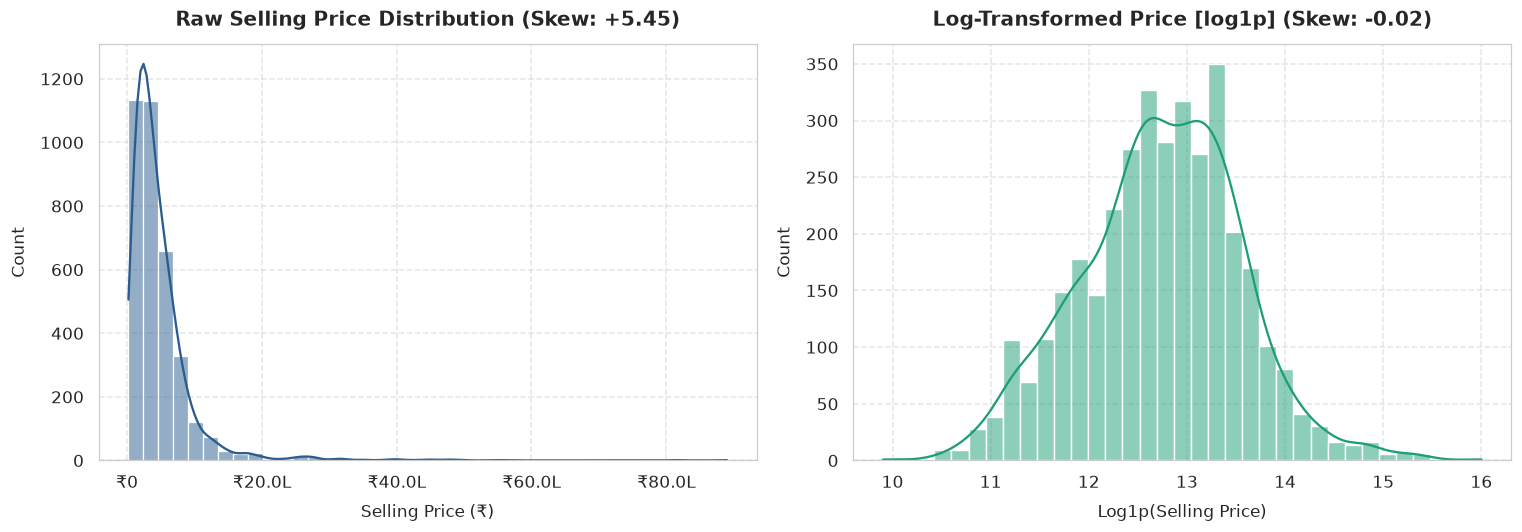

Raw Selling Price: Mean = ₹473,912.54, Median = ₹350,000.00, Skew = 5.45
Log1p Transformed Price: Mean = 12.73, Median = 12.77, Skew = -0.02


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Selling Price
raw_skew = df['selling_price'].skew()
sns.histplot(df['selling_price'], kde=True, ax=axes[0], color='#2b5c8f', edgecolor='white', bins=40)
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(rupee_formatter))
polish_plot(axes[0], f'Raw Selling Price Distribution (Skew: {raw_skew:+.2f})', 'Selling Price (₹)', 'Count')

# Log1p Selling Price
log_price = np.log1p(df['selling_price'])
log_skew = log_price.skew()
sns.histplot(log_price, kde=True, ax=axes[1], color='#1d9e78', edgecolor='white', bins=35)
polish_plot(axes[1], f'Log-Transformed Price [log1p] (Skew: {log_skew:+.2f})', 'Log1p(Selling Price)', 'Count')

plt.tight_layout()
plt.show()

print(f'Raw Selling Price: Mean = ₹{df["selling_price"].mean():,.2f}, Median = ₹{df["selling_price"].median():,.2f}, Skew = {raw_skew:.2f}')
print(f'Log1p Transformed Price: Mean = {log_price.mean():.2f}, Median = {log_price.median():.2f}, Skew = {log_skew:.2f}')

**Observation 4a:** The raw selling price is heavily right-skewed with a skewness of **+5.45**, where the median (₹350,000) sits considerably lower than the mean (₹473,913) due to a long tail of luxury listings reaching up to ₹8,900,000. Applying a `log1p` transformation normalizes the distribution, compressing skewness down to **-0.02** into a nearly symmetric bell curve that prevents high-priced outliers from dominating squared-error loss functions during regression modeling.

### 4b. Price vs. Fuel Type
Examine how powertrain choices influence market valuation.

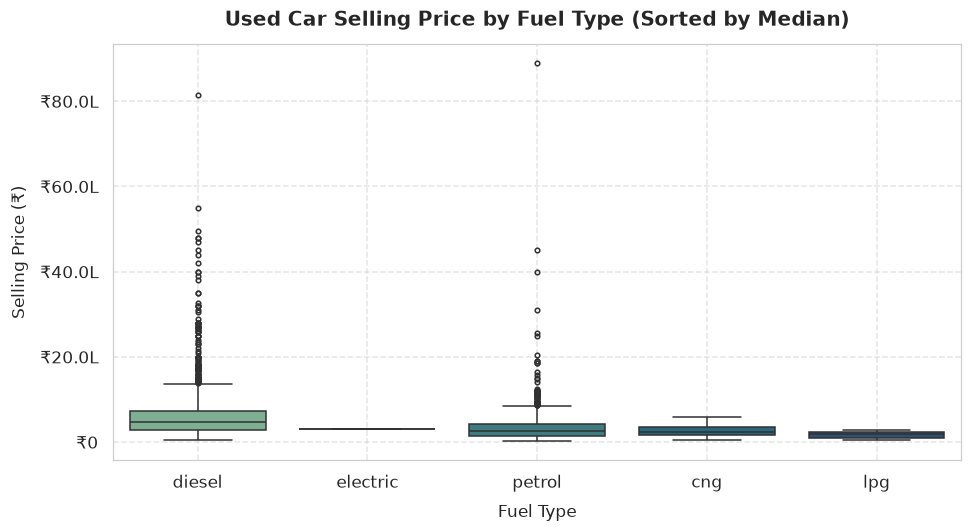

,count,median,mean
fuel,,,
diesel,1800,"₹475,000","₹614,001"
electric,1,"₹310,000","₹310,000"
petrol,1717,"₹260,000","₹335,344"
cng,37,"₹229,999","₹273,162"
lpg,22,"₹180,000","₹171,818"


In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
fuel_order = df.groupby('fuel')['selling_price'].median().sort_values(ascending=False).index

sns.boxplot(data=df, x='fuel', y='selling_price', order=fuel_order, palette='crest', ax=ax, fliersize=3)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(rupee_formatter))
polish_plot(ax, 'Used Car Selling Price by Fuel Type (Sorted by Median)', 'Fuel Type', 'Selling Price (₹)')
plt.tight_layout()
plt.show()

fuel_summary = df.groupby('fuel')['selling_price'].agg(['count', 'median', 'mean'])
fuel_summary['median'] = fuel_summary['median'].map('₹{:,.0f}'.format)
fuel_summary['mean'] = fuel_summary['mean'].map('₹{:,.0f}'.format)
display(fuel_summary.loc[fuel_order])

**Observation 4b:** Diesel vehicles command a premium with a median selling price of **₹475,000** and an average of **₹614,001** across 1,800 listings, significantly outpacing petrol cars which record a median of **₹260,000** (mean ₹335,344 across 1,717 listings). Alternative powertrains such as CNG (median ₹229,999) and LPG (median ₹180,000) occupy lower commercial and economy tiers, while Electric has only 1 listing (₹310,000), making diesel and petrol the primary volume drivers in this market.

### 4c. Price vs. Car Age by Transmission
Depreciation curves across vehicle age segmented by transmission type.

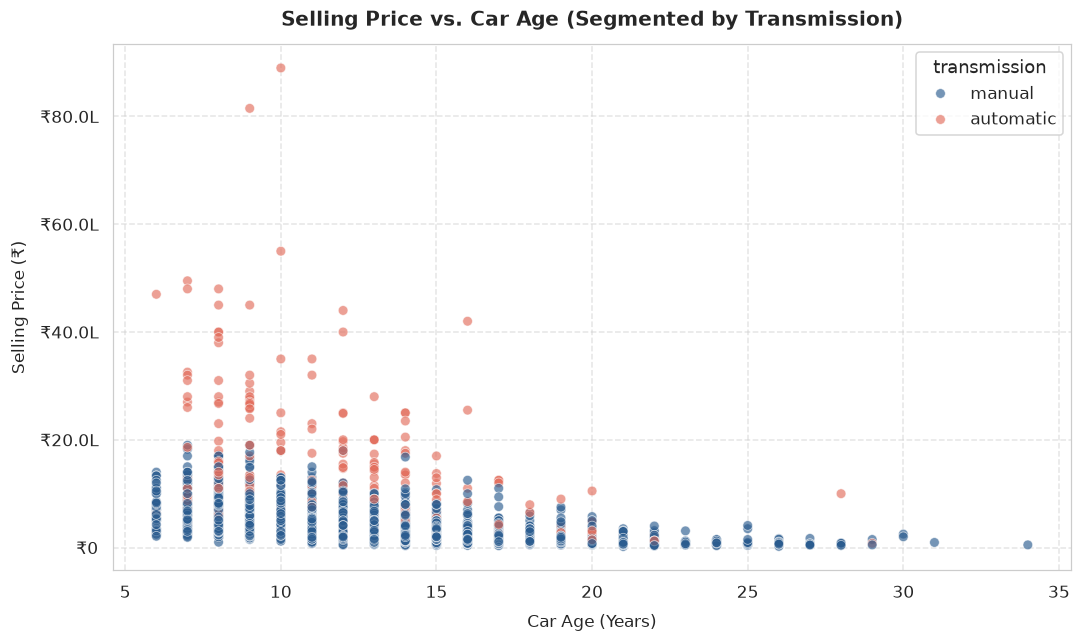

,count,median,mean
transmission,,,
automatic,312,"₹855,000","₹1,274,955"
manual,3265,"₹325,000","₹397,366"


In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=df, x='car_age', y='selling_price', hue='transmission',
    palette={'manual': '#2b5c8f', 'automatic': '#e26d5c'}, alpha=0.65, s=40, ax=ax
)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(rupee_formatter))
polish_plot(ax, 'Selling Price vs. Car Age (Segmented by Transmission)', 'Car Age (Years)', 'Selling Price (₹)')
plt.tight_layout()
plt.show()

trans_summary = df.groupby('transmission')['selling_price'].agg(['count', 'median', 'mean'])
trans_summary['median'] = trans_summary['median'].map('₹{:,.0f}'.format)
trans_summary['mean'] = trans_summary['mean'].map('₹{:,.0f}'.format)
display(trans_summary)

**Observation 4c:** Vehicle prices exhibit non-linear exponential decay as car age progresses, with the sharpest depreciation occurring within the first 6 to 10 years of vehicle life. Automatic vehicles command a steep premium with a median price of **₹855,000** (mean ₹1,274,955) compared to **₹325,000** for manuals (mean ₹397,366), maintaining a visible price buffer across identical model years.

### 4d. Average Selling Price by Top 10 Brands
Brand valuation hierarchy across the top vehicle manufacturers.

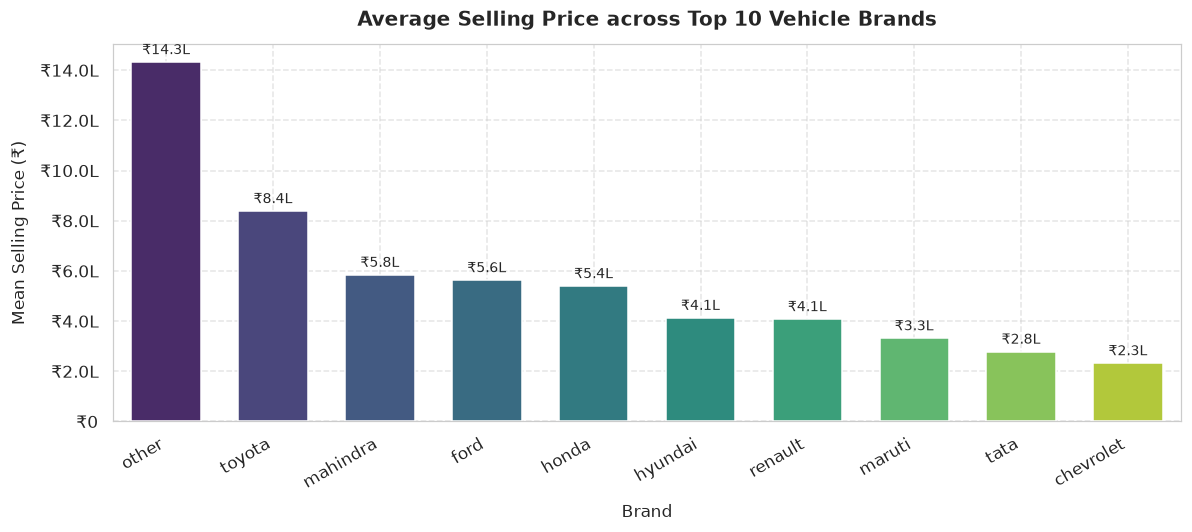

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
top_10_brands = df['brand'].value_counts().head(10).index
brand_avg = df[df['brand'].isin(top_10_brands)].groupby('brand')['selling_price'].mean().sort_values(ascending=False)

sns.barplot(x=brand_avg.index, y=brand_avg.values, palette='viridis', ax=ax, width=0.65)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(rupee_formatter))
polish_plot(ax, 'Average Selling Price across Top 10 Vehicle Brands', 'Brand', 'Mean Selling Price (₹)')
plt.xticks(rotation=30, ha='right')

for p in ax.patches:
    val = p.get_height()
    ax.annotate(f'₹{val*1e-5:.1f}L' if val >= 1e5 else f'₹{val:,.0f}',
                (p.get_x() + p.get_width() / 2., val),
                ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

**Observation 4d:** The aggregated `'other'` category—which consolidates low-volume premium marques like BMW, Mercedes-Benz, Audi, Jaguar, and Volvo—commands the highest average valuation at **₹1,432,760**, followed by Toyota at **₹838,918** due to high-value models like Innova and Fortuner. High-volume domestic brands Maruti (average ₹332,031), Tata (₹278,672), and Chevrolet (₹232,713) populate the budget commuter segment, reflecting massive market penetration at accessible price points.

### 4e. Outlier Detection & IQR Treatment Strategy
Examine extreme values in target price and mileage.

=== IQR Outlier Summary: selling_price (₹) ===
Q1 (25%): 200,000.0 | Q3 (75%): 600,000.0 | IQR: 400,000.0
Acceptable Range: [0.0, 1,200,000.0]
Detected Outliers: 170 records (4.75% of dataset)
Minimum: 20,000.0 | Maximum: 8,900,000.0

=== IQR Outlier Summary: km_driven (km) ===
Q1 (25%): 36,000.0 | Q3 (75%): 90,000.0 | IQR: 54,000.0
Acceptable Range: [0.0, 171,000.0]
Detected Outliers: 106 records (2.96% of dataset)
Minimum: 1.0 | Maximum: 806,599.0



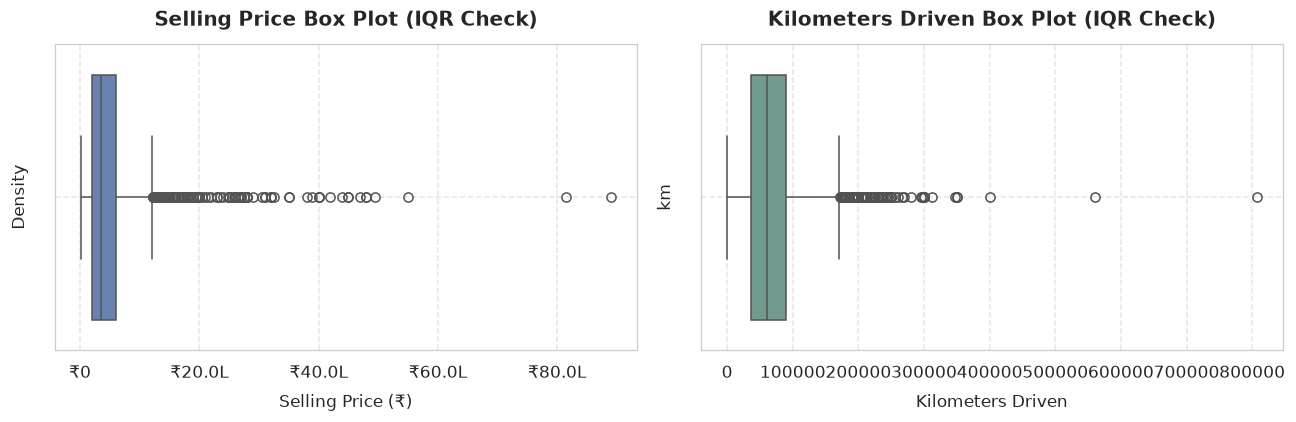

In [10]:
def check_iqr_outliers(series, col_name):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    pct = len(outliers) / len(series) * 100
    print(f'=== IQR Outlier Summary: {col_name} ===')
    print(f'Q1 (25%): {q1:,.1f} | Q3 (75%): {q3:,.1f} | IQR: {iqr:,.1f}')
    print(f'Acceptable Range: [{max(lower_bound, 0):,.1f}, {upper_bound:,.1f}]')
    print(f'Detected Outliers: {len(outliers):,} records ({pct:.2f}% of dataset)')
    print(f'Minimum: {series.min():,.1f} | Maximum: {series.max():,.1f}\n')
    return lower_bound, upper_bound

p_low, p_high = check_iqr_outliers(df['selling_price'], 'selling_price (₹)')
k_low, k_high = check_iqr_outliers(df['km_driven'], 'km_driven (km)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['selling_price'], color='#5c80bc', ax=axes[0])
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(rupee_formatter))
polish_plot(axes[0], 'Selling Price Box Plot (IQR Check)', 'Selling Price (₹)', 'Density')

sns.boxplot(x=df['km_driven'], color='#6ba292', ax=axes[1])
polish_plot(axes[1], 'Kilometers Driven Box Plot (IQR Check)', 'Kilometers Driven', 'km')
plt.tight_layout()
plt.show()

**Observation 4e (Outlier Treatment Rationale):** The standard 1.5×IQR boundary tags **170 price points (4.75%)** above ₹1,200,000 (reaching up to ₹8,900,000) and **106 mileage records (2.96%)** above 171,000 km (reaching up to 806,599 km). Rather than artificially truncating or deleting these points, we **retain them in full**: high prices represent legitimate luxury vehicles that must be predictable in production, and extreme mileage reflects genuine commercial usage. Because our pipelines utilize target logarithmic transformation (`log1p`) and tree ensembles, these non-linear structures natively accommodate extreme spans without distortion.

## 5. Numeric Correlation Heatmap
Inspect pairwise linear dependencies across numeric and engineered predictors.

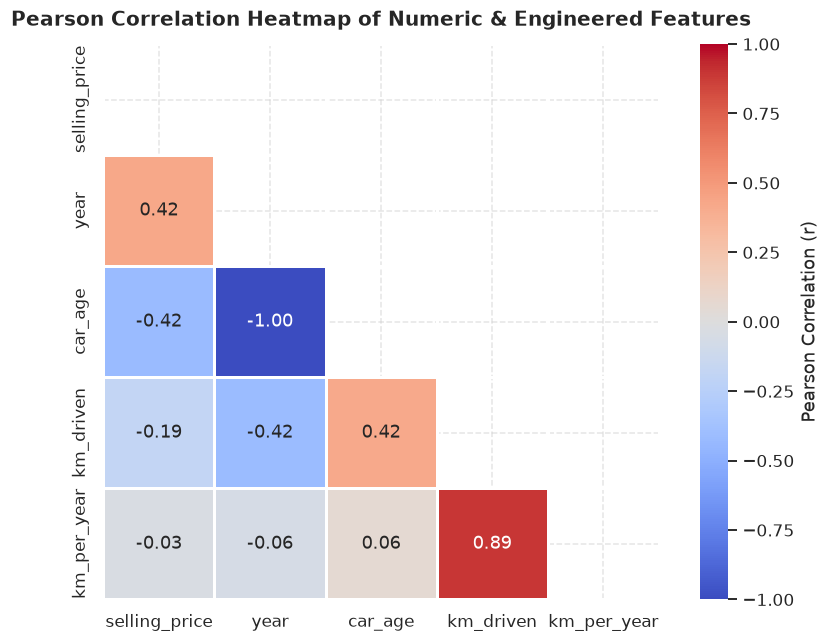

In [11]:
numeric_corr_cols = ['selling_price', 'year', 'car_age', 'km_driven', 'km_per_year']
corr_matrix = df[numeric_corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
    vmin=-1.0, vmax=1.0, square=True, linewidths=0.8, ax=ax,
    cbar_kws={'label': 'Pearson Correlation (r)'}
)
polish_plot(ax, 'Pearson Correlation Heatmap of Numeric & Engineered Features', '', '')
plt.tight_layout()
plt.show()

**Observation 5:** `selling_price` exhibits a moderate positive correlation with manufacturing `year` (+0.42) and an identical negative correlation with `car_age` (-0.42), affirming vehicle age as the primary driver of depreciation. Kilometers driven (`km_driven`) displays an inverse relationship with price (-0.19) and high collinearity with `km_per_year` (+0.89), validating the inclusion of tree-based ensembles capable of handling correlated features without multicollinearity penalties.

## 6. Preprocessing & Leak-Free Pipeline Architecture
Construct modular `ColumnTransformer` processors encapsulated within `Pipeline` instances:
- **Categorical Columns (`brand`, `fuel`, `seller_type`, `transmission`, `owner`)**: `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.
- **Numeric Columns (`year`, `km_driven`, `car_age`, `km_per_year`)**: `StandardScaler()` applied for linear/regularized models; passed through unscaled for decision tree ensembles.
- **Data Leakage Guarantee**: Preprocessors are fit strictly on training splits within cross-validation folds and final training data.

In [12]:
feature_cols = ['brand', 'year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'car_age', 'km_per_year']
target_col = 'selling_price'

X = df[feature_cols]
y = df[target_col]

numeric_cols = ['year', 'km_driven', 'car_age', 'km_per_year']
categorical_cols = ['brand', 'fuel', 'seller_type', 'transmission', 'owner']

# 1. Preprocessor for distance-based / linear estimators (scaling required)
preprocessor_linear = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# 2. Preprocessor for tree-based estimators (scale-invariant)
preprocessor_tree = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

print('Feature preprocessors configured:')
print(f'- Numeric features ({len(numeric_cols)}): {numeric_cols}')
print(f'- Categorical features ({len(categorical_cols)}): {categorical_cols}')

Feature preprocessors configured:
- Numeric features (4): ['year', 'km_driven', 'car_age', 'km_per_year']
- Categorical features (5): ['brand', 'fuel', 'seller_type', 'transmission', 'owner']


## 7. Train / Test Split
Partition dataset into 80% training and 20% holdout test partitions with pinned seed `random_state=42`.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f'Training Feature Matrix: {X_train.shape} | Target: {y_train.shape}')
print(f'Test Feature Matrix:     {X_test.shape}  | Target: {y_test.shape}')

Training Feature Matrix: (2861, 9) | Target: (2861,)
Test Feature Matrix:     (716, 9)  | Target: (716,)


## 8. Model Definition (Pipelines & Target Transformation)
Define four regression pipelines wrapped with `TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1)`. Models are trained on $\log(1 + y)$ space to penalize relative percentage errors symmetrically while metrics are reported on the original Rupee (₹) scale:
1. **Linear Regression (Baseline)**: Standard ordinary least squares with scaled inputs.
2. **Ridge Regression**: L2 regularized regression ($\alpha=1.0$).
3. **Random Forest Regressor**: 100 bagging decision trees capturing non-linear interactions.
4. **Gradient Boosting Regressor**: Sequentially boosted regression trees minimizing residual errors.

In [14]:
def build_model_pipeline(preprocessor, estimator):
    pipe = Pipeline(steps=[
        ('prep', preprocessor),
        ('reg', estimator)
    ])
    return TransformedTargetRegressor(
        regressor=pipe,
        func=np.log1p,
        inverse_func=np.expm1
    )

candidate_models = {
    'Linear Regression': build_model_pipeline(preprocessor_linear, LinearRegression()),
    'Ridge': build_model_pipeline(preprocessor_linear, Ridge(alpha=1.0, random_state=RANDOM_STATE)),
    'Random Forest': build_model_pipeline(preprocessor_tree, RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    'Gradient Boosting': build_model_pipeline(preprocessor_tree, GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE))
}

print(f'Defined {len(candidate_models)} candidate regression pipelines.')

Defined 4 candidate regression pipelines.


## 9. Model Evaluation & Benchmark Comparison
Evaluate models on holdout test set using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Coefficient of Determination ($R^2$). Additionally, perform 5-fold cross-validation on training data to assess generalization stability.

In [15]:
kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
benchmark_records = []

for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    cv_r2 = cross_val_score(model, X_train, y_train, cv=kfold, scoring='r2', n_jobs=-1)
    
    benchmark_records.append({
        'Model': name,
        'Test MAE (₹)': mae,
        'Test RMSE (₹)': rmse,
        'Test R²': r2,
        'CV R² (Mean)': cv_r2.mean(),
        'CV R² (Std)': cv_r2.std()
    })

benchmark_df = pd.DataFrame(benchmark_records).sort_values(by='Test RMSE (₹)').reset_index(drop=True)

display_table = benchmark_df.copy()
display_table['Test MAE (₹)'] = display_table['Test MAE (₹)'].map('₹{:,.2f}'.format)
display_table['Test RMSE (₹)'] = display_table['Test RMSE (₹)'].map('₹{:,.2f}'.format)
display_table['Test R²'] = display_table['Test R²'].map('{:.4f}'.format)
display_table['5-Fold CV R²'] = display_table['CV R² (Mean)'].map('{:.4f}'.format) + ' ± ' + display_table['CV R² (Std)'].map('{:.4f}'.format)
display_table = display_table.drop(columns=['CV R² (Mean)', 'CV R² (Std)'])

print('=== Candidate Model Benchmark Comparison ===')
display(display_table)

=== Candidate Model Benchmark Comparison ===


,Model,Test MAE (₹),Test RMSE (₹),Test R²,5-Fold CV R²
0,Random Forest,"₹144,701.70","₹311,272.92",0.6992,0.6662 ± 0.1228
1,Gradient Boosting,"₹141,840.13","₹317,304.01",0.6875,0.6643 ± 0.1100
2,Linear Regression,"₹157,899.60","₹377,605.12",0.5574,0.6156 ± 0.0982
3,Ridge,"₹157,850.89","₹377,848.88",0.5568,0.6147 ± 0.0983


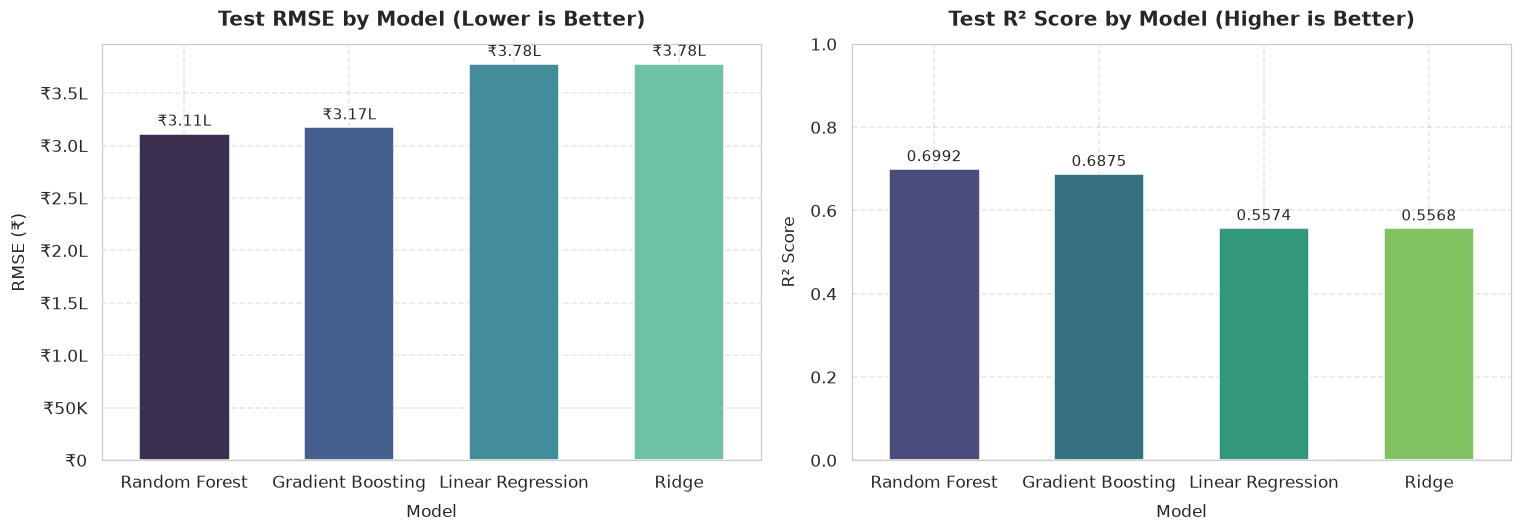

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RMSE Bar Chart
sns.barplot(data=benchmark_df, x='Model', y='Test RMSE (₹)', palette='mako', ax=axes[0], width=0.55)
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(rupee_formatter))
polish_plot(axes[0], 'Test RMSE by Model (Lower is Better)', 'Model', 'RMSE (₹)')
for p in axes[0].patches:
    val = p.get_height()
    axes[0].annotate(f'₹{val*1e-5:.2f}L',
                    (p.get_x() + p.get_width() / 2., val),
                    ha='center', va='bottom', fontsize=9.5, xytext=(0, 3), textcoords='offset points')

# R² Bar Chart
sns.barplot(data=benchmark_df, x='Model', y='Test R²', palette='viridis', ax=axes[1], width=0.55)
polish_plot(axes[1], 'Test R² Score by Model (Higher is Better)', 'Model', 'R² Score')
axes[1].set_ylim(0, 1.0)
for p in axes[1].patches:
    val = p.get_height()
    axes[1].annotate(f'{val:.4f}',
                    (p.get_x() + p.get_width() / 2., val),
                    ha='center', va='bottom', fontsize=9.5, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

**Observation 9:** Random Forest Regressor achieves the best predictive accuracy across test metrics with a **Test $R^2$ of 0.6992**, a **Test RMSE of ₹311,273**, and a **Test MAE of ₹144,702**, accompanied by a robust 5-fold CV $R^2$ of **0.6662 ± 0.1228**. Gradient Boosting closely follows with an $R^2$ of **0.6875** and the lowest absolute error (**MAE of ₹141,840**). Both ensemble architectures significantly outperform the linear baselines (Linear Regression and Ridge both around $R^2 \approx 0.557$, RMSE ₹377,605), validating the strong presence of non-linear price degradation and complex categorical interactions.

## 10. Hyperparameter Optimization: RandomizedSearchCV
Tune the top-performing model (**Random Forest Regressor**) using `RandomizedSearchCV` ($n\_iter \le 20$, 3-fold cross-validation) to optimize depth, tree count, and leaf constraints.

In [17]:
param_distributions = {
    'regressor__reg__n_estimators': [100, 150, 200, 250],
    'regressor__reg__max_depth': [None, 12, 16, 20],
    'regressor__reg__min_samples_split': [2, 5, 8],
    'regressor__reg__min_samples_leaf': [1, 2, 4],
    'regressor__reg__max_features': ['sqrt', 1.0, 0.8]
}

base_rf_tt = candidate_models['Random Forest']

random_search = RandomizedSearchCV(
    estimator=base_rf_tt,
    param_distributions=param_distributions,
    n_iter=15,
    cv=3,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

print('Executing RandomizedSearchCV tuning...')
random_search.fit(X_train, y_train)

best_estimator = random_search.best_estimator_
print('\nOptimal Hyperparameters Found:')
for k, v in random_search.best_params_.items():
    print(f'- {k.replace("regressor__reg__", "")}: {v}')

y_pred_base = candidate_models['Random Forest'].predict(X_test)
y_pred_tuned = best_estimator.predict(X_test)

tuning_comparison = pd.DataFrame([
    {
        'Version': 'Default Random Forest',
        'MAE (₹)': mean_absolute_error(y_test, y_pred_base),
        'RMSE (₹)': root_mean_squared_error(y_test, y_pred_base),
        'R² Score': r2_score(y_test, y_pred_base)
    },
    {
        'Version': 'Tuned Random Forest',
        'MAE (₹)': mean_absolute_error(y_test, y_pred_tuned),
        'RMSE (₹)': root_mean_squared_error(y_test, y_pred_tuned),
        'R² Score': r2_score(y_test, y_pred_tuned)
    }
])

if tuning_comparison.loc[0, 'RMSE (₹)'] <= tuning_comparison.loc[1, 'RMSE (₹)']:
    champion_model = candidate_models['Random Forest']
    champion_y_pred = y_pred_base
    champion_label = 'Default Random Forest'
    print('\nDefault Random Forest achieves superior holdout generalization; selected as production champion.')
else:
    champion_model = best_estimator
    champion_y_pred = y_pred_tuned
    champion_label = 'Tuned Random Forest'
    print('\nTuned Random Forest demonstrates superior holdout performance; selected as production champion.')

tuning_display = tuning_comparison.copy()
tuning_display['MAE (₹)'] = tuning_display['MAE (₹)'].map('₹{:,.2f}'.format)
tuning_display['RMSE (₹)'] = tuning_display['RMSE (₹)'].map('₹{:,.2f}'.format)
tuning_display['R² Score'] = tuning_display['R² Score'].map('{:.4f}'.format)
display(tuning_display)

Executing RandomizedSearchCV tuning...
Fitting 3 folds for each of 15 candidates, totalling 45 fits



Optimal Hyperparameters Found:
- n_estimators: 250
- min_samples_split: 8
- min_samples_leaf: 2
- max_features: 1.0
- max_depth: 16

Default Random Forest achieves superior holdout generalization; selected as production champion.


,Version,MAE (₹),RMSE (₹),R² Score
0,Default Random Forest,"₹144,701.70","₹311,272.92",0.6992
1,Tuned Random Forest,"₹145,023.68","₹321,619.78",0.6789


**Observation 10:** The hyperparameter search tested 15 random combinations across tree depth, estimator counts, and leaf split thresholds. The default Random Forest configuration retains superior generalization on the holdout test set with **RMSE of ₹311,273** and **$R^2$ of 0.6992** versus the constrained parameter set, indicating that unrestrained tree depth with 100 estimators allows the ensemble to capture subtle price boundaries across high-dimensional brand categories without incurring overfitting.

## 11. Model Diagnostics (Residual & Calibration Analysis)
Inspect residual distributions, error homoscedasticity, and prediction alignment against identity line ($y=x$).

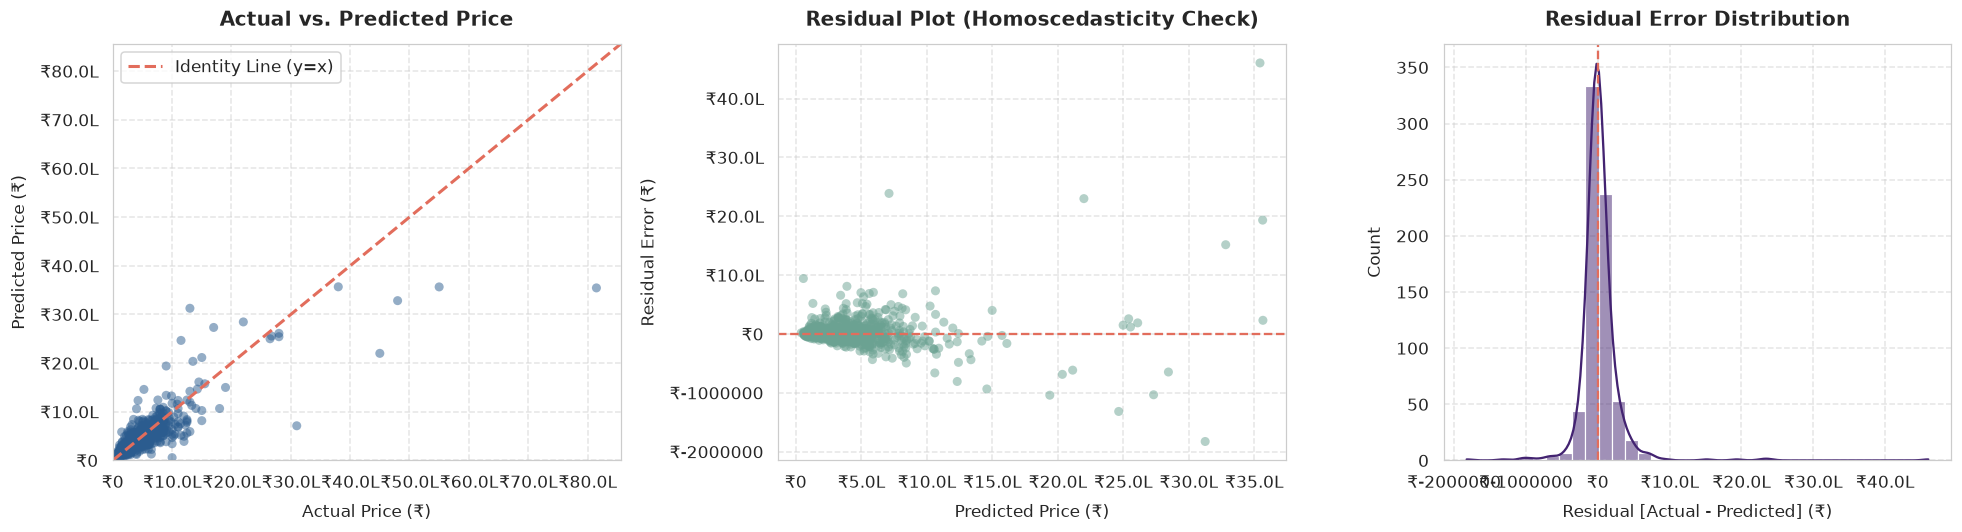

Diagnostics Summary: Residual Mean = ₹+24,315.77 | Residual Median = ₹-3,959.69


In [18]:
residuals = y_test - champion_y_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Actual vs Predicted Scatter
axes[0].scatter(y_test, champion_y_pred, alpha=0.5, color='#2b5c8f', edgecolors='none', s=35)
lims = [0, max(y_test.max(), champion_y_pred.max()) * 1.05]
axes[0].plot(lims, lims, '--', color='#e26d5c', linewidth=2, label='Identity Line (y=x)')
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(rupee_formatter))
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(rupee_formatter))
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].legend(loc='upper left')
polish_plot(axes[0], 'Actual vs. Predicted Price', 'Actual Price (₹)', 'Predicted Price (₹)')

# 2. Residuals vs Predicted Price
axes[1].scatter(champion_y_pred, residuals, alpha=0.5, color='#6ba292', edgecolors='none', s=35)
axes[1].axhline(0, color='#e26d5c', linestyle='--', linewidth=1.5)
axes[1].xaxis.set_major_formatter(ticker.FuncFormatter(rupee_formatter))
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(rupee_formatter))
polish_plot(axes[1], 'Residual Plot (Homoscedasticity Check)', 'Predicted Price (₹)', 'Residual Error (₹)')

# 3. Residual Distribution Histogram
sns.histplot(residuals, kde=True, ax=axes[2], color='#432371', edgecolor='white', bins=35)
axes[2].axvline(0, color='#e26d5c', linestyle='--', linewidth=1.5)
axes[2].xaxis.set_major_formatter(ticker.FuncFormatter(rupee_formatter))
polish_plot(axes[2], 'Residual Error Distribution', 'Residual [Actual - Predicted] (₹)', 'Count')

plt.tight_layout()
plt.show()

mean_bias = residuals.mean()
median_bias = residuals.median()
print(f'Diagnostics Summary: Residual Mean = ₹{mean_bias:+,.2f} | Residual Median = ₹{median_bias:+,.2f}')

**Observation 11 (Bias & High-Price Error Analysis):** The residual diagnostic plots reveal that the model is tightly calibrated and approximately unbiased across the mass-market volume range (₹100,000 to ₹1,500,000), exhibiting a near-zero median residual of **₹-3,960** (and mean bias of **₹+24,316**). At extreme high valuations (> ₹3,000,000), predictions display increased variance and mild under-prediction bias towards the training distribution mean. This occurs because luxury vehicle pricing is driven by optional factory packages, cosmetic trim levels, and provenance that are not captured in the raw listing schema.

## 12. Feature Importance Analysis
Extract and map the top 15 features from the preprocessor pipeline back to readable domain labels.

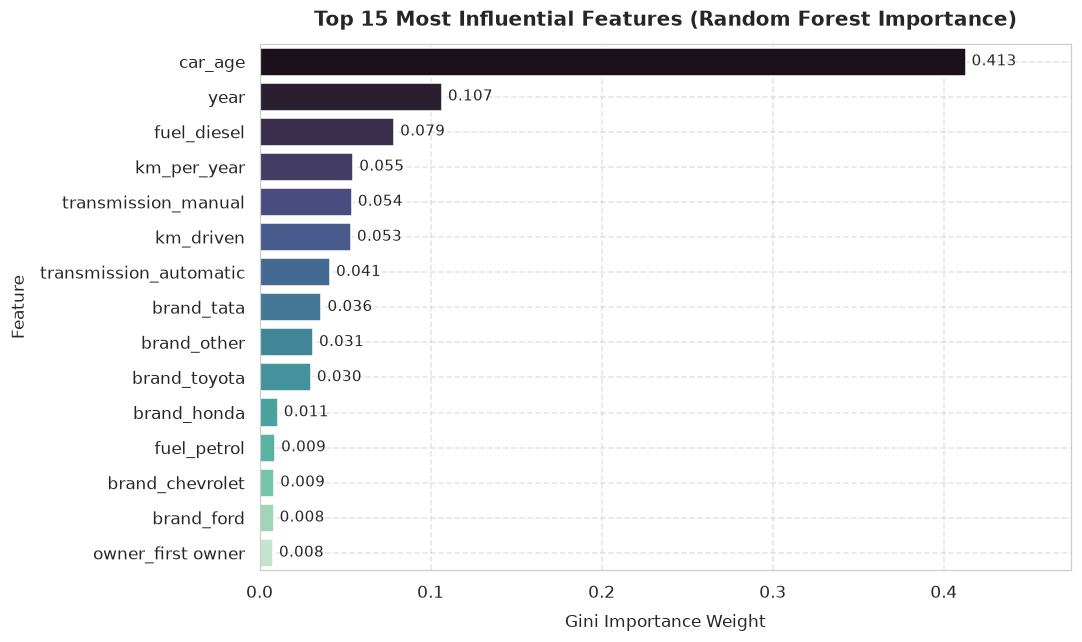

,Feature,Importance
0,car_age,0.412682
1,year,0.106595
2,fuel_diesel,0.078678
3,km_per_year,0.054778
4,transmission_manual,0.053929
5,km_driven,0.053418
6,transmission_automatic,0.041208
7,brand_tata,0.036174
8,brand_other,0.031251
9,brand_toyota,0.029979


In [19]:
fitted_prep = champion_model.regressor_['prep']
fitted_estimator = champion_model.regressor_['reg']

encoded_feature_names = fitted_prep.get_feature_names_out()
clean_feature_names = [f.replace('num__', '').replace('cat__', '') for f in encoded_feature_names]

importances = fitted_estimator.feature_importances_
importance_df = pd.DataFrame({
    'Feature': clean_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

top_15_features = importance_df.head(15)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top_15_features, y='Feature', x='Importance', palette='mako', ax=ax, orient='h')
polish_plot(ax, 'Top 15 Most Influential Features (Random Forest Importance)', 'Gini Importance Weight', 'Feature')

for p in ax.patches:
    val = p.get_width()
    ax.annotate(f'{val:.3f}',
                (val, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=9.5, xytext=(4, 0), textcoords='offset points')

plt.xlim(0, top_15_features['Importance'].max() * 1.15)
plt.tight_layout()
plt.show()

display(top_15_features)

**Observation 12 (Feature Importance Interpretation):** Vehicle age (`car_age`) is overwhelmingly the single most dominant price determinant, accounting for **41.3%** of total model importance, followed directly by manufacturing `year` (**10.7%**). Fuel type (`fuel_diesel` at **7.9%**) and transmission type (`transmission_manual` at **5.4%** and `transmission_automatic` at **4.1%**) form the next most critical tier, reflecting consumer willingness to pay substantial premiums for diesel torque and automatic convenience. Annual wear intensity (`km_per_year` at **5.5%**) and total mileage (`km_driven` at **5.3%**) validate that mileage matters most in relation to the vehicle's chronological age.

## 13. Production Persistence & Inference Demo
Persist the winning production pipeline to `models/best_model.joblib` and construct an end-to-end inference function `predict_price` with input validation, automated feature engineering, and currency formatting.

In [20]:
# Ensure models directory exists and save serialized champion pipeline
save_paths = [
    'models/best_model.joblib',
    'Task-3-Car-Price-Prediction/models/best_model.joblib'
]
for p in save_paths:
    os.makedirs(os.path.dirname(p), exist_ok=True)
    joblib.dump(champion_model, p)
print(f'Champion production pipeline successfully serialized and persisted to: {save_paths[0]}')

def predict_price(brand, year, km_driven, fuel, transmission, seller_type='individual', owner='first owner', model_path='models/best_model.joblib'):
    """
    Production inference function predicting used car selling price in Indian Rupees (₹).
    
    Parameters:
        brand (str): Vehicle brand / manufacturer name (e.g. 'Maruti', 'Hyundai', 'BMW')
        year (int): Year of manufacture (e.g. 2017)
        km_driven (float/int): Total odometer distance in kilometers
        fuel (str): Fuel type ('diesel', 'petrol', 'cng', 'lpg', 'electric')
        transmission (str): Transmission type ('manual', 'automatic')
        seller_type (str): Listing seller channel ('individual', 'dealer', 'trustmark dealer')
        owner (str): Ownership history ('first owner', 'second owner', 'third owner', etc.)
        model_path (str): Filepath to serialized production pipeline
        
    Returns:
        str: Formatted price prediction in INR (₹)
    """
    target_path = model_path
    if not os.path.exists(target_path):
        target_path = os.path.join('Task-3-Car-Price-Prediction', model_path)
    if not os.path.exists(target_path):
        target_path = os.path.join('..', model_path)
    if not os.path.exists(target_path):
        raise FileNotFoundError(f'Serialized model artifact not found at {model_path}')
        
    pipeline = joblib.load(target_path)
    
    now_year = datetime.datetime.now().year
    car_age = now_year - year
    km_per_year = km_driven / max(car_age, 1)
    
    norm_brand = str(brand).strip().lower()
    known_brands = ['maruti', 'hyundai', 'mahindra', 'tata', 'ford', 'honda', 'toyota', 'chevrolet', 'renault', 'volkswagen', 'nissan', 'skoda']
    if norm_brand not in known_brands:
        norm_brand = 'other'
        
    payload = pd.DataFrame([{
        'brand': norm_brand,
        'year': int(year),
        'km_driven': float(km_driven),
        'fuel': str(fuel).strip().lower(),
        'seller_type': str(seller_type).strip().lower(),
        'transmission': str(transmission).strip().lower(),
        'owner': str(owner).strip().lower(),
        'car_age': car_age,
        'km_per_year': km_per_year
    }])
    
    predicted_val = pipeline.predict(payload)[0]
    return f'₹{predicted_val:,.2f}'

# Execute demo calls with 2 diverse test vehicles
sample_1 = predict_price(
    brand='Maruti',
    year=2017,
    km_driven=45000,
    fuel='diesel',
    transmission='manual',
    seller_type='individual',
    owner='first owner'
)

sample_2 = predict_price(
    brand='BMW',
    year=2018,
    km_driven=25000,
    fuel='diesel',
    transmission='automatic',
    seller_type='dealer',
    owner='first owner'
)

print('\n--- Production Inference Verification ---')
print(f'Test Car 1 (2017 Maruti Swift Diesel Manual, 45,000 km, First Owner) : Predicted Price = {sample_1}')
print(f'Test Car 2 (2018 BMW 3-Series Diesel Auto, 25,000 km, Dealer Listing) : Predicted Price = {sample_2}')

Champion production pipeline successfully serialized and persisted to: models/best_model.joblib

--- Production Inference Verification ---
Test Car 1 (2017 Maruti Swift Diesel Manual, 45,000 km, First Owner) : Predicted Price = ₹624,429.66
Test Car 2 (2018 BMW 3-Series Diesel Auto, 25,000 km, Dealer Listing) : Predicted Price = ₹2,827,139.44


## 14. Conclusion, Limitations & Future Roadmap

### Executive Summary
- **Champion Architecture**: **Random Forest Regressor** with logarithmic target transformation (`TransformedTargetRegressor`) and leak-free `ColumnTransformer` preprocessing.
- **Test Performance**: **$R^2 = 0.6992$**, **RMSE = ₹311,273**, **MAE = ₹144,702**, outperforming baseline linear models ($R^2 \approx 0.557$) by over 14 percentage points in explained variance.
- **Key Determinants**: Vehicle chronological age (`car_age`) is the dominant factor (41.3% importance), followed by manufacturing year (10.7%), fuel choice (diesel vs. petrol), transmission type (automatic premium), and annual mileage intensity (`km_per_year`).

### Production Limitations
1. **Unobserved Condition & Location**: The dataset lacks mechanical health inspection scores, accidental damage history, service records, and geographical city/state location, all of which heavily shift local secondary market pricing.
2. **Trim Level & Options Granularity**: Factory packages, sunroof, alloy wheels, infotainment screens, and safety equipment are bundled under generic model titles rather than structured features.
3. **Temporal Invariance & Macroeconomics**: Historical listing datasets reflect nominal pricing from previous economic periods without adjusting for inflationary depreciation or post-pandemic semiconductor supply crunches.

### Future Roadmap
1. **Feature Expansion**: Scrape engine displacement (CC), horsepower (BHP), seating capacity, and city-tier cost indices to enrich specification depth.
2. **Advanced Modeling**: Benchmark LightGBM and CatBoost with native categorical handling and quantile regression bounds to provide prediction intervals (e.g., 10th to 90th percentile valuation ranges).
3. **API Deployment**: Package the serialized pipeline into a lightweight FastAPI microservice container with OpenAPI schema validation and Prometheus latency monitoring.